# Optimisation

We offer a few minimum examples for phylogenetic optimisation schemes using Phylo2Vec objects, including:
* A hill-climbing scheme using Phylo2Vec vectors, with branch length optimisation using [RAxML-NG](https://github.com/amkozlov/raxml-ng)
* [GradME](https://doi.org/10.1093/gbe/evad213), a continuous optimisation scheme based on a probabilistic version of Phylo2Vec.

Running this notebook requires the optional dependencies (`pip install phylo2vec[opt]`), [RAxML-NG](https://github.com/amkozlov/raxml-ng) for hill-climbing, and R with the [ape](https://cran.r-project.org/package=ape) package for GradME.

## Imports and data

In [ ]:
import os
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from ete4 import Tree
from urllib.request import urlretrieve

import phylo2vec as p2v
from phylo2vec.utils.newick import apply_label_mapping

All available optimisation schemes can be found using `list_methods`

In [ ]:
from phylo2vec.opt import list_methods

list_methods()

['GradME', 'HillClimbing']


As an example, we will look at a simple H3N2 dataset offered with the TreeTime package, available [here](https://github.com/neherlab/treetime_examples/blob/master/data/h3n2_na/h3n2_na_20.fasta).

In [ ]:
# Temporary directory for the data and the trees written during optimisation
work_dir = tempfile.mkdtemp()

fasta_path = os.path.join(work_dir, "h3n2_na_20.fa")

urlretrieve(
    "https://raw.githubusercontent.com/neherlab/treetime_examples/79eae7f8025a8ef3165c856c7359d92e738eb893/data/h3n2_na/h3n2_na_20.fasta",
    fasta_path,
)

('/tmp/tmpc7g4ak2b/h3n2_na_20.fa', <http.client.HTTPMessage at 0x78fd651e5850>)

## 1. Hill-climbing

A hill-climbing scheme for tree optimisation is described in the Phylo2Vec [paper](https://doi.org/10.1093/sysbio/syae030). The general idea is to sample a random index $i$ of the vector, evaluate proposals (in [0, 2*i]), and pick the tree which has the largest change in likelihood compared to our current best. To avoid getting stuck in local optima, we perform random re-rooting operations to change equivalences without changing the likelihood.

The only required argument is `model`, a [substitution model](https://en.wikipedia.org/wiki/Models_of_DNA_evolution) name (as a string).

In [ ]:
from phylo2vec.opt import HillClimbing

hc = HillClimbing(model="GTR", tree_folder_path=work_dir, verbose=True)

hc_result = hc.fit(fasta_path)

Changing equivalences...
Start step: 4089.278
Loss: 4089.278 (diff: -0.000)
Loss: 4087.434 (diff: -1.844)
Loss: 4039.590 (diff: -47.844)
Loss: 4037.555 (diff: -2.036)
Loss: 4033.972 (diff: -3.583)
Loss: 3999.460 (diff: -34.512)
Loss: 3992.570 (diff: -6.890)
Loss: 3987.452 (diff: -5.118)
Loss: 3930.095 (diff: -57.357)
Loss: 3895.441 (diff: -34.654)
Loss: 3871.407 (diff: -24.034)
Loss: 3871.407 (diff: -0.000)
Loss: 3858.784 (diff: -12.623)
Loss: 3624.946 (diff: -233.838)
Loss: 3623.626 (diff: -1.320)
Loss: 3490.827 (diff: -132.799)
End step: 3490.827
Changing equivalences...
Start step: 3490.828
Loss: 3490.828 (diff: -0.000)
Loss: 3490.828 (diff: -0.000)
Loss: 3477.114 (diff: -13.714)
Loss: 3473.728 (diff: -3.386)
Loss: 3449.168 (diff: -24.560)
Loss: 3421.395 (diff: -27.773)
Loss: 3409.448 (diff: -11.947)
Loss: 3402.158 (diff: -7.290)
Loss: 3400.540 (diff: -1.619)
Loss: 3395.976 (diff: -4.563)
End step: 3395.976
Changing equivalences...
Start step: 3395.976
Loss: 3395.976 (diff: -0.000)


`hc_result` contains several objects:
 * the best topology
 * a label_mapping to convert the tree back to a Newick with taxon labels
 * the best score (here, the negative log-likelihood of the best tree)
 * all scores obtained during the optimisation

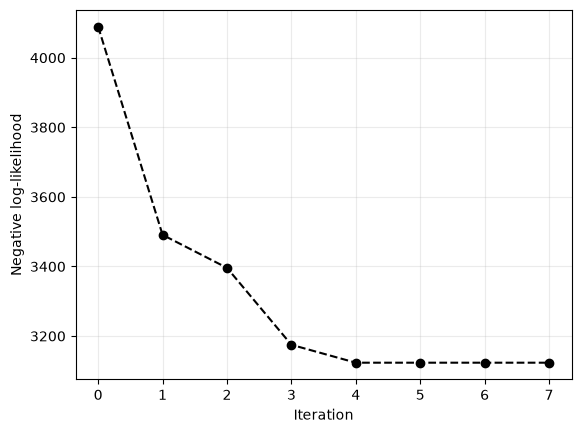

In [ ]:
plt.plot(hc_result.scores, "ko--")
plt.xlabel("Iteration")
plt.ylabel("Negative log-likelihood")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
hc_newick = p2v.to_newick(hc_result.best)

hc_newick_with_taxa = apply_label_mapping(hc_newick, hc_result.label_mapping)

print(Tree(hc_newick_with_taxa))

       ╭─┬╴A/New_Hampshire/12/2012|KF790252|11/08/2012|USA|12_13|H3N2/1-1409
       │ ╰─┬╴A/Boston/DOA2_107/2012|CY148382|11/01/2012|USA|12_13|H3N2/1-1409
     ╭─┤   ╰─┬╴A/Maryland/03/2013|KF789621|02/10/2013|USA|12_13|H3N2/1-1409
   ╭─┤ │     ╰╴A/Hawaii/02/2013|KF789866|05/28/2013|USA|12_13|H3N2/1-1409
   │ │ ╰╴A/Indiana/03/2012|KC892731|04/03/2012|USA|11_12|H3N2/1-1409
 ╭─┤ ╰─┬╴A/Nebraska/15/2011|KC892583|12/15/2011|USA|11_12|H3N2/1-1409
 │ │   ╰╴A/Maryland/21/2011|KC892695|12/26/2011|USA|11_12|H3N2/1-1409
 │ ╰╴A/Peru/PER247/2011|CY162234|08/26/2011|Peru||H3N2/8-1416
─┤ ╭╴A/Minab/797/2011|KC865620|12/24/2011|Iran||H3N2/20-1428
 │ │         ╭╴A/Mexico/InDRE940/2003|CY100628|2003|Mexico||H3N2/15-1423
 │ │       ╭─┤ ╭╴A/New_York/182/2000|CY001279|02/18/2000|USA|99_00|H3N2/1-1409
 ╰─┤       │ ╰─┤ ╭─┬╴A/Scotland/76/2003|CY088128|11/03/2003|United_Kingdom|03_04|H3N2/1-1409
   │     ╭─┤   ╰─┤ ╰╴A/Denmark/107/2003|EU103941|2003|Denmark||H3N2/1-1409
   │   ╭─┤ │     ╰╴A/Canterbury/58/2000|CY0

## 2. GradME

GradME constitutes an attempt to perform continuous phylogenetic inference using gradient descent and balanced minimum evolution (for a review, see [here](https://doi.org/10.1016/j.ejor.2021.08.004)), thus implying that GradME tries to minimise the path length of the tree.

It involves a continuous tree representation based on `ordered` Phylo2Vec trees, with a matrix W of shape ($n-1, n-1$) for a tree of $n$ leaves. For $i \in [0, n-2], j \in [0, n-2], W_{ij} = P(v_i = j)$, where $v$ a Phylo2Vec vector.

Given the Phylo2Vec constraints, $W$ is a lower-triangular, stochastic matrix (row sum to 1). The most likely single tree from W can be obtained by taking the row-wise argmax: ```v = W.argmax(1)```.

To improve search, GradME also relies on `Queue Shuffle`, a taxon reordering algorithm to allow for full tree space exploration.

For more details, see the paper: <https://doi.org/10.1093/gbe/evad213>

From an implementation point of view, GradME is based on `jax` and `optax`. It is thus advised to run it on a GPU to experience speed-ups! The only required argument is `model`, a [substitution model](https://en.wikipedia.org/wiki/Models_of_DNA_evolution) name (as a string).

In [ ]:
from phylo2vec.opt import GradME

# To run the GradME optimizer, we need to specify a substitution model.
gradme = GradME(model="F81", solver="adabelief", patience=10, learning_rate=0.1, tol=1e-10, verbose=True, nesterov=True)

gradme_result = gradme.fit(fasta_path)

[2026-11-02 09:16:32,596] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
[2026-11-02 09:16:32,597] Unable to initialize backend 'proxy': The 'proxy' backend requires the address of an IFRT Proxy server. Set it via the JAX_BACKEND_TARGET environment variable or the jax_backend_target config option, e.g. JAX_BACKEND_TARGET=grpc://localhost:29000.
 34%|███▍      | 34/100 [02:15<04:23,  4.00s/it, Current loss: -2.079899]


Early stopping after 10 iterations without improvement.
Optimisation finished in 137.86 seconds with 35 loss evaluations.


`gradme_result` contains several objects:
 * the best topology
 * a label_mapping to convert the tree back to a Newick with taxon labels
 * the best score (here, the logarithm of the balanced minimum evolution length of the best tree)
 * all scores obtained during the optimisation
 * the best set of weights (`best_W`) corresponding to a probabilistic ordered tree

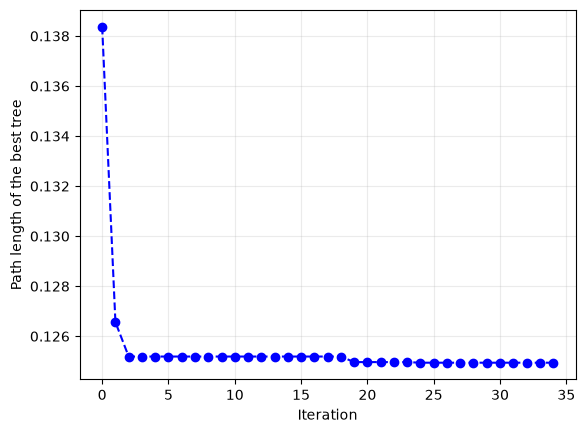

In [ ]:
plt.plot(np.exp(gradme_result.scores), "bo--")
plt.xlabel("Iteration")
plt.ylabel("Path length of the best tree")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
gradme_newick = p2v.to_newick(np.asarray(gradme_result.best))

gradme_newick_with_taxa = apply_label_mapping(gradme_newick, gradme_result.label_mapping)

print(Tree(gradme_newick_with_taxa))

   ╭╴A/Scotland/76/2003|CY088128|11/03/2003|United_Kingdom|03_04|H3N2/1-1409
 ╭─┤ ╭─┬╴A/New_York/182/2000|CY001279|02/18/2000|USA|99_00|H3N2/1-1409
 │ │ │ ╰╴A/Canterbury/58/2000|CY009150|09/05/2000|New_Zealand||H3N2/8-1416
 │ ╰─┤ ╭╴A/Mexico/InDRE940/2003|CY100628|2003|Mexico||H3N2/15-1423
 │   │ │ ╭╴A/Managua/25/2007|CY032439|06/27/2007|Nicaragua||H3N2/1-1409
 │   ╰─┤ │   ╭╴A/Boston/57/2008|CY044710|02/24/2008|USA|07_08|H3N2/1-1409
 │     │ │ ╭─┤ ╭─┬╴A/Hong_Kong/H090_695_V10/2009|CY115546|07/10/2009|Hong_Kong||H3N2/8-1416
 │     ╰─┤ │ ╰─┤ ╰╴A/Oregon/15/2009|GQ895004|06/25/2009|USA|08_09|H3N2/1-1409
 │       │ │   │ ╭╴A/Minab/797/2011|KC865620|12/24/2011|Iran||H3N2/20-1428
─┤       │ │   ╰─┤ ╭╴A/Peru/PER247/2011|CY162234|08/26/2011|Peru||H3N2/8-1416
 │       │ │     ╰─┤ ╭─┬╴A/Nebraska/15/2011|KC892583|12/15/2011|USA|11_12|H3N2/1-1409
 │       ╰─┤       ╰─┤ ╰╴A/Maryland/21/2011|KC892695|12/26/2011|USA|11_12|H3N2/1-1409
 │         │         │ ╭╴A/Indiana/03/2012|KC892731|04/03/2012|USA|11

<Axes: >

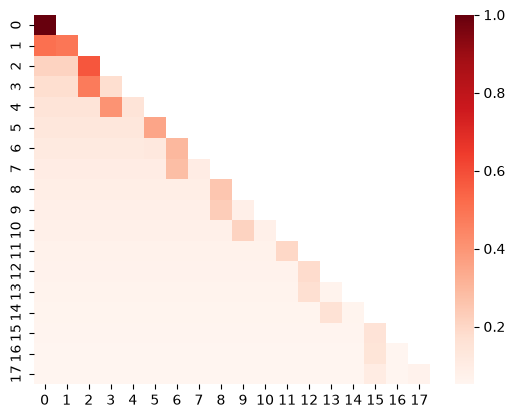

In [ ]:
sns.heatmap(
    gradme_result.best_W,
    cmap="Reds",
    mask=np.triu(np.ones_like(gradme_result.best_W, dtype=bool), k=1)
)